# Ecobici — Impacto ambiental de la política de redistribución propuesta

En este notebook se analiza el impacto ambiental potencial de implementar una estrategia optimizada de redistribución de bicicletas en la subred de Ecobici conformada por las estaciones de Buenavista y Reforma estudiadas en las etapas anteriores.

A partir de los resultados del modelo estocástico, la optimización de la política del camión y las simulaciones de escenarios, se busca estimar:

- La reducción de rechazos por falta de bicicletas y espacios disponibles.
- El incremento potencial de viajes en bicicleta.
- La posible sustitución de viajes en vehículos particulares.
- La reducción potencial de emisiones de CO₂.
- El impacto ambiental asociado a la redistribución de bicicletas.
- La incertidumbre de las estimaciones bajo diferentes escenarios de demanda.

El objetivo es determinar si la política propuesta, además de mejorar el funcionamiento del sistema, podría generar beneficios ambientales.

Los resultados representan estimaciones basadas en el modelo y no beneficios ambientales observados directamente.

## 1. Obtención y preparación de datos

### 1.1 Configuración del entorno

Se importan las librerías necesarias para el análisis.
Se utilizarán los resultados previamente obtenidos para mantener la consistencia entre el modelo estocástico, la política de redistribución y el análisis ambiental.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

### 1.2 Identificación de los archivos disponibles

Antes de realizar los cálculos ambientales, se identifican los archivos generados en las etapas anteriores del proyecto.

Estos archivos contienen información sobre el comportamiento de las estaciones, las políticas de redistribución y los resultados de las simulaciones.

La finalidad es identificar las fuentes de información necesarias para el análisis ambiental, sin volver a ejecutar los modelos previamente desarrollados.

In [2]:
ruta = Path.cwd()

archivos_csv = list(ruta.rglob("*.csv"))

for archivo in archivos_csv:
    print(archivo.relative_to(ruta))

outputs/tablas/camion_politicas.csv
outputs/tablas/log_limpieza.csv
outputs/tablas/camion_validacion.csv
outputs/tablas/sim_variacion_dias.csv
outputs/tablas/resumen_meses.csv
outputs/tablas/camion_actual_hora.csv
outputs/tablas/escenarios.csv
outputs/tablas/sim_escenarios.csv
outputs/tablas/camion_frontera.csv
outputs/tablas/prob_falla_hora.csv
outputs/tablas/mejor_x0.csv
outputs/tablas/justificacion_mm1n.csv
outputs/tablas/rechazos_x0.csv
outputs/tablas/sim_validacion_kolmogorov.csv
outputs/tablas/sim_validacion_datos.csv
outputs/tablas/control_archivos.csv
outputs/tablas/lotes.csv
outputs/tablas/tasas_modelo.csv
outputs/tablas/validacion_huecos.csv
outputs/tablas/camion_actual.csv
outputs/tablas/descriptivas_estacion_hora.csv
outputs/tablas/camion_propuesta.csv
outputs/tablas/sim_criterios.csv
outputs/tablas/validacion_meses.csv
outputs/tablas/log_limpieza_2026-09.csv


### 1.3 Selección de las fuentes de información

De los archivos disponibles se seleccionan principalmente los siguientes:

| Archivo | Información utilizada |
|---|---|
| camion_politicas.csv | Comparación de rechazos y demanda atendida entre políticas. |
| sim_escenarios.csv | Resultados de las simulaciones bajo diferentes niveles de demanda. |
| camion_actual.csv | Movimientos de bicicletas bajo la política actual. |
| camion_propuesta.csv | Movimientos de bicicletas bajo la política optimizada. |

La información de estos archivos permitirá comparar el funcionamiento actual del sistema con la estrategia propuesta y estimar sus posibles beneficios ambientales.

In [3]:
ruta_tablas = ruta / "outputs" / "tablas"

sim_escenarios = pd.read_csv(ruta_tablas / "sim_escenarios.csv")
camion_actual = pd.read_csv(ruta_tablas / "camion_actual.csv")
camion_propuesta = pd.read_csv(ruta_tablas / "camion_propuesta.csv")
camion_politicas = pd.read_csv(ruta_tablas / "camion_politicas.csv")

### 1.4 Exploración de los resultados previos

Se realiza una revisión de los archivos seleccionados
para identificar las variables que serán utilizadas
en el análisis ambiental.

Las principales variables de interés son:

- Rechazos por falta de bicicletas.
- Rechazos por falta de espacios disponibles (docks).
- Porcentaje de demanda atendida.
- Bicicletas redistribuidas por el camión.
- Resultados bajo diferentes niveles de demanda.

Estas variables permitirán relacionar la mejora operativa
del sistema con sus posibles beneficios ambientales.

In [4]:
print("SIMULACIÓN DE ESCENARIOS")
display(sim_escenarios.head())

print("POLÍTICA ACTUAL")
display(camion_actual.head())

print("POLÍTICA PROPUESTA")
display(camion_propuesta.head())

print("COMPARACIÓN DE POLÍTICAS")
display(camion_politicas.head())

SIMULACIÓN DE ESCENARIOS


,política,escenario,rechazos (media),IC 95 %,rechazos P95,% demanda atendida,bicis movidas
0,sin camión,baja,1056.4,7.6,1257.0,65.2,0.0
1,actual,baja,232.7,5.5,396.0,92.3,998.8
2,propuesta,baja,115.3,2.6,189.0,96.2,964.3
3,propuesta (camión de 40),baja,201.6,4.9,339.0,93.3,876.7
4,sin camión,base,1092.2,7.3,1293.0,64.9,0.0


POLÍTICA ACTUAL


,Unnamed: 0,grupo,saca (día),deja (día),saca (noche),deja (noche)
0,271-272,Buenavista,376.157895,233.000000,45.105263,15.789474
1,273-274,Buenavista,93.368421,40.894737,19.947368,7.684211
2,014,Reforma,93.105263,40.842105,1.368421,0.105263
3,027,Reforma,49.473684,31.526316,1.157895,0.315789
4,018,Reforma,58.789474,31.526316,0.631579,0.000000


POLÍTICA PROPUESTA


,estación,hora,frontera,deja la estación con,bicis que deja (prom.),bicis que saca (prom.),bicis movidas (p95)
0,271-272,7:00,4,72,54.4,0.0,72
1,271-272,8:00,6,72,54.6,0.0,72
2,271-272,8:30,7,72,52.5,0.0,70
3,271-272,9:00,8,65,45.5,0.0,63
4,271-272,9:30,9,57,26.7,0.0,41


COMPARACIÓN DE POLÍTICAS


,política,estación,x0,sin bici,sin dock,rechazos,% demanda atendida,horas vacía,horas llena,bicis dejadas,bicis sacadas
0,sin camión,271-272,74.0,262.44,425.65,688.09,42.40,4.45,5.43,0.00,0.00
1,actual,271-272,74.0,38.94,65.38,104.32,91.27,1.37,1.00,225.67,370.31
2,sin camión,273-274,70.0,66.77,95.64,162.41,60.72,3.88,5.38,0.00,0.00
3,actual,273-274,70.0,29.41,12.51,41.92,89.86,2.24,1.63,38.11,90.41
4,sin camión,014,0.0,32.10,84.29,116.39,76.31,3.05,2.77,0.00,0.00


## 2. Reducción de rechazos

### 2.1 Comparación de rechazos por política

Para determinar la mejora en la disponibilidad del servicio,
se comparan tres estrategias de redistribución:

- Sin camión: el sistema funciona sin redistribución.
- Actual: representa la política actual modelada.
- Propuesta: representa la estrategia optimizada.

Se suman los rechazos esperados de las cinco estaciones,
diferenciando entre los ocasionados por falta de bicicletas
y aquellos ocasionados por falta de espacios disponibles.

Desde una perspectiva ambiental, los rechazos por falta
de bicicletas son especialmente relevantes, ya que
representan oportunidades de viaje que no pudieron
ser atendidas.

In [5]:
resumen_rechazos = camion_politicas.groupby("política")[
    ["sin bici", "sin dock", "rechazos",
     "bicis dejadas", "bicis sacadas"]
].sum()

display(resumen_rechazos.round(2))

,sin bici,sin dock,rechazos,bicis dejadas,bicis sacadas
política,,,,,
actual,106.27,100.53,206.80,356.99,650.89
propuesta,56.31,46.34,102.66,354.46,650.10
sin camión,401.27,687.70,1088.97,0.00,0.00


#### Interpretación de los resultados

La política propuesta reduce los rechazos esperados
de 206.80 a 102.66 por día, lo que representa una
disminución del 50.36%.

Los rechazos por falta de bicicletas disminuyen de
106.27 a 56.31, evitando aproximadamente 49.96 rechazos
diarios de retiro.

Por otro lado, los rechazos por falta de espacios
disponibles disminuyen de 100.53 a 46.34 por día.

Desde una perspectiva ambiental, las 49.96 oportunidades
adicionales de retiro serán utilizadas como punto de
partida para estimar los viajes adicionales en bicicleta.

Sin embargo, no se puede asegurar que todas estas
oportunidades se conviertan en viajes adicionales ni
que sustituyan directamente viajes en automóvil.

### 2.2 Comparación de escenarios de demanda

La demanda de bicicletas puede variar dependiendo
del día, los horarios y las condiciones externas.

Por esta razón, se analiza el comportamiento de la
política propuesta bajo tres escenarios de demanda:
baja, base y alta.

La cantidad de rechazos evitados se calcula mediante:

$$
R_{evitados} = R_{actual} - R_{propuesta}
$$

Mientras que el porcentaje de reducción se obtiene como:

$$
Reducción (\%) =
\frac{R_{actual}-R_{propuesta}}{R_{actual}}
\times 100
$$

El objetivo es determinar si los beneficios de la
estrategia propuesta se mantienen ante diferentes
niveles de demanda.

In [6]:
comparacion_escenarios = sim_escenarios.pivot(
    index="escenario",
    columns="política",
    values="rechazos (media)"
)

comparacion_escenarios["rechazos evitados"] = (
    comparacion_escenarios["actual"] -
    comparacion_escenarios["propuesta"]
)

comparacion_escenarios["reducción (%)"] = (
    comparacion_escenarios["rechazos evitados"] /
    comparacion_escenarios["actual"] * 100
)

display(comparacion_escenarios.round(2))

política,actual,propuesta,propuesta (camión de 40),sin camión,rechazos evitados,reducción (%)
escenario,,,,,,
alta,410.9,187.7,339.0,1286.5,223.2,54.32
baja,232.7,115.3,201.6,1056.4,117.4,50.45
base,270.6,126.4,226.2,1092.2,144.2,53.29


#### Interpretación de los resultados

La política propuesta presenta una reducción superior
al 50% de los rechazos en los tres escenarios analizados.

- Demanda baja: se evitan 117.4 rechazos diarios,
  equivalentes a una reducción del 50.45%.

- Demanda base: se evitan 144.2 rechazos diarios,
  equivalentes a una reducción del 53.29%.

- Demanda alta: se evitan 223.2 rechazos diarios,
  equivalentes a una reducción del 54.32%.

Los resultados muestran que la estrategia propuesta
mantiene sus beneficios incluso cuando aumenta la
demanda del servicio.

El mayor beneficio se presenta en el escenario de
demanda alta, donde se evita una mayor cantidad de
rechazos.

Esto indica que la estrategia podría generar mayores
beneficios operativos durante los días de mayor demanda.

### 2.3 Visualización de la reducción de rechazos

Se construyen dos gráficas comparativas para facilitar
la interpretación de los resultados.

La primera muestra la cantidad de rechazos por falta
de bicicletas y espacios disponibles para cada política.

La segunda compara los rechazos totales de la política
actual y la propuesta bajo los diferentes escenarios
de demanda.

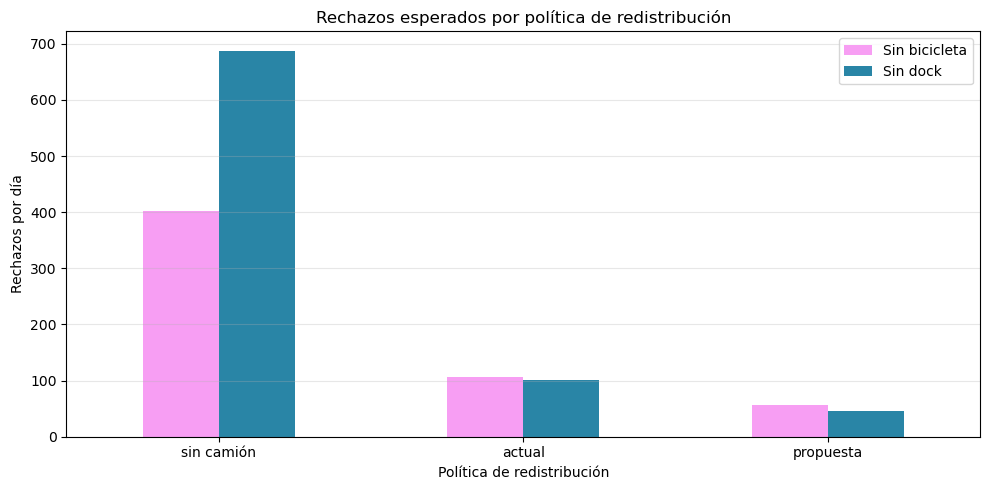

In [12]:
orden_politicas = ["sin camión", "actual", "propuesta"]

resumen_rechazos.loc[orden_politicas, [
    "sin bici", "sin dock"
]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#F79EF3", "#2985a6"],
    rot=0
)

plt.title("Rechazos esperados por política de redistribución")
plt.xlabel("Política de redistribución")
plt.ylabel("Rechazos por día")
plt.legend(["Sin bicicleta", "Sin dock"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

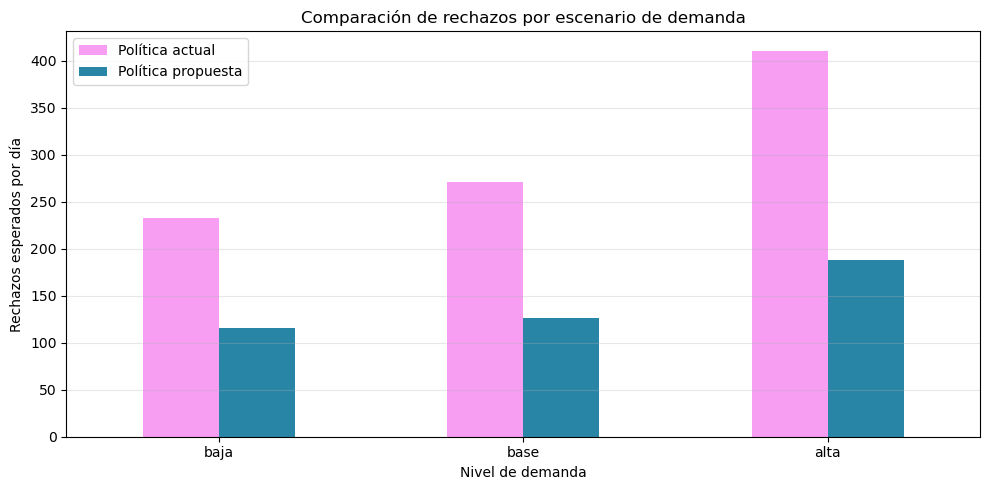

In [11]:
orden_escenarios = ["baja", "base", "alta"]

comparacion_escenarios.loc[orden_escenarios, [
    "actual", "propuesta"
]].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#F79EF3", "#2985a6"],
    rot=0
)

plt.title("Comparación de rechazos por escenario de demanda")
plt.xlabel("Nivel de demanda")
plt.ylabel("Rechazos esperados por día")
plt.legend(["Política actual", "Política propuesta"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()